In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/niravnaik/safety-helmet-and-reflective-jacket/safety-Helmet-Reflective-Jacket/data.yaml
/kaggle/input/datasets/niravnaik/safety-helmet-and-reflective-jacket/safety-Helmet-Reflective-Jacket/test/images/helmet_jacket_07350.jpg
/kaggle/input/datasets/niravnaik/safety-helmet-and-reflective-jacket/safety-Helmet-Reflective-Jacket/test/images/helmet_jacket_07351.jpg
/kaggle/input/datasets/niravnaik/safety-helmet-and-reflective-jacket/safety-Helmet-Reflective-Jacket/test/images/helmet_jacket_07352.jpg
/kaggle/input/datasets/niravnaik/safety-helmet-and-reflective-jacket/safety-Helmet-Reflective-Jacket/test/images/helmet_jacket_07353.jpg
/kaggle/input/datasets/niravnaik/safety-helmet-and-reflective-jacket/safety-Helmet-Reflective-Jacket/test/images/helmet_jacket_07354.jpg
/kaggle/input/datasets/niravnaik/safety-helmet-and-reflective-jacket/safety-Helmet-Reflective-Jacket/test/images/helmet_jacket_07355.jpg
/kaggle/input/datasets/niravnaik/safety-helmet-and-reflective-jacke

In [2]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 12.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics] [ultralytics]


In [3]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
import seaborn as sns
import cv2
from ultralytics import YOLO
import warnings
warnings.filterwarnings('ignore')
# 关闭此 Notebook 的 Weights 和 Biases (wandb) 报告功能
os.environ['WANDB_DISABLED'] = 'true'

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [4]:
model = YOLO('yolo11n.pt')

In [5]:
!yolo train \
    model = yolo11n.pt \
    data = /kaggle/input/datasets/niravnaik/safety-helmet-and-reflective-jacket/safety-Helmet-Reflective-Jacket/data.yaml \
    epochs = 30 \
    imgsz = 640 \
    batch = 64 \
    device = 0,1

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
                                                        CUDA:1 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=64, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/input/datasets/niravnaik/safety-helmet-and-reflective-jacket/safety-Helmet-Reflective-Jacket/data.yaml, degrees=0.0, deterministic=True, device=0,1, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_rati

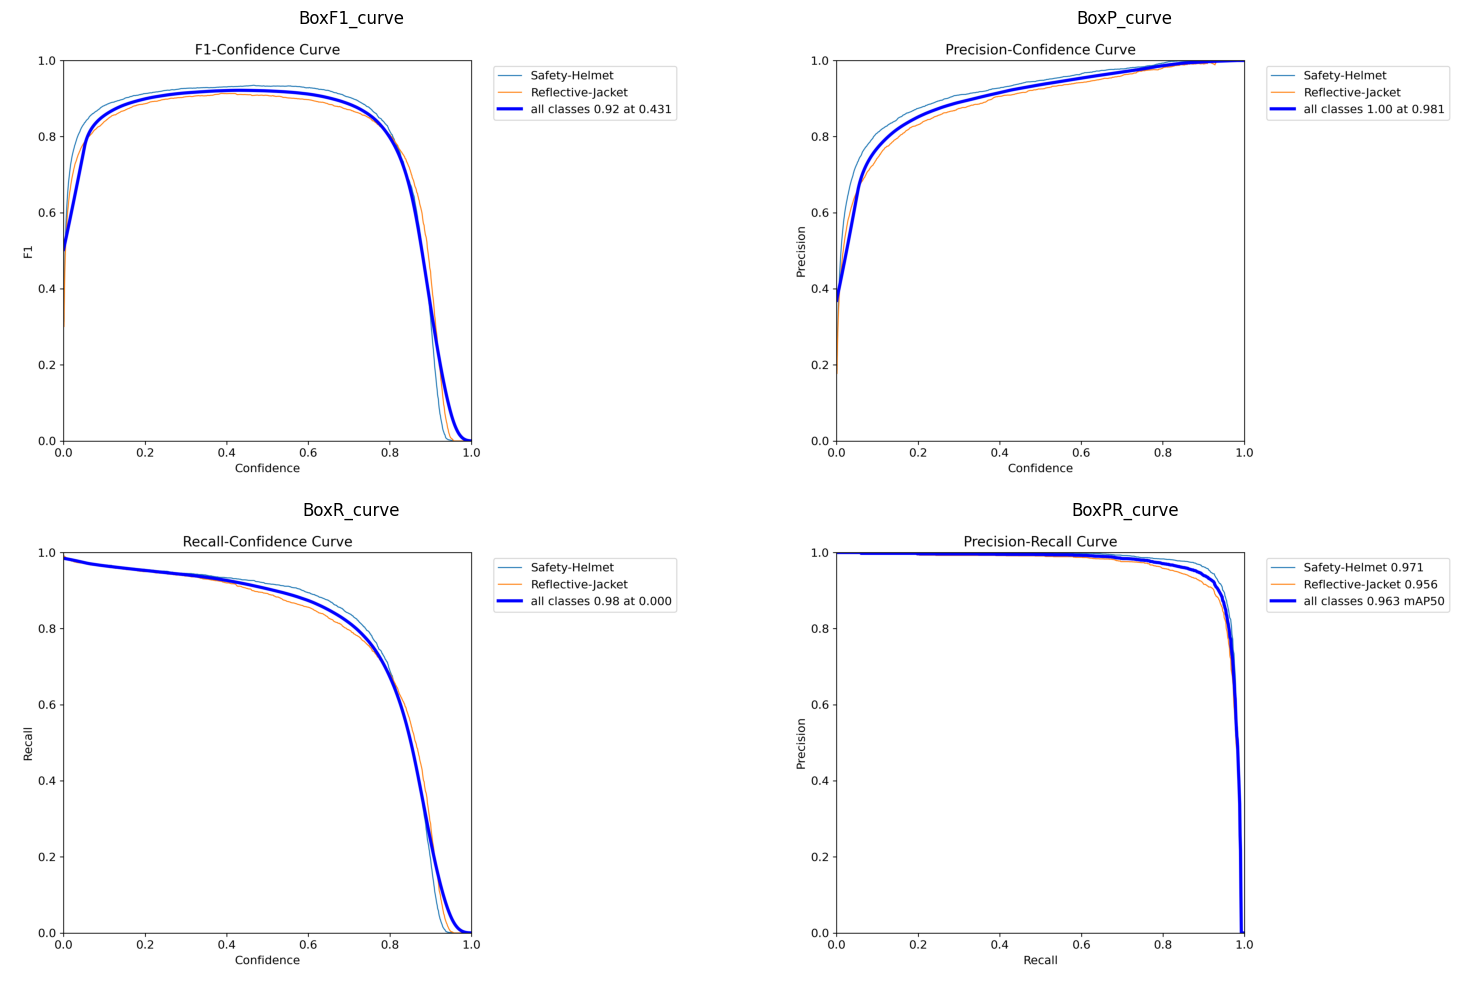

In [8]:
# 指定性能评估曲线的图片所在的目录
directory = '/kaggle/working/runs/detect/train'

# 定义要展示的图片文件名
image_files = [
    'BoxF1_curve.png',
    'BoxP_curve.png',
    'BoxR_curve.png',
    'BoxPR_curve.png'
]

# 创建一个包含 4 个子图的图形
fig, axes = plt.subplots(2, 2, figsize = (16, 10))
axes = axes.flatten() # 将二维数组展平为一维数组以便索引

# 遍历每个图片文件并加载到相应的子图中
for ax, image_file in zip(axes, image_files):
    image_path = os.path.join(directory, image_file)
    if os.path.exists(image_path):
        img = plt.imread(image_path)
        ax.imshow(img)
        ax.set_title(os.path.splitext(image_file)[0]) # 设置子图标题为图片文件名（去掉扩展名）
        ax.axis('off') # 关闭坐标轴
    else:
        ax.text(0.5, 0.5, f"File not found: {image_file}", ha = 'center', va = 'center', fontsize = 12)
        ax.axis('off')

# 调整子图间距
plt.tight_layout()
plt.show()


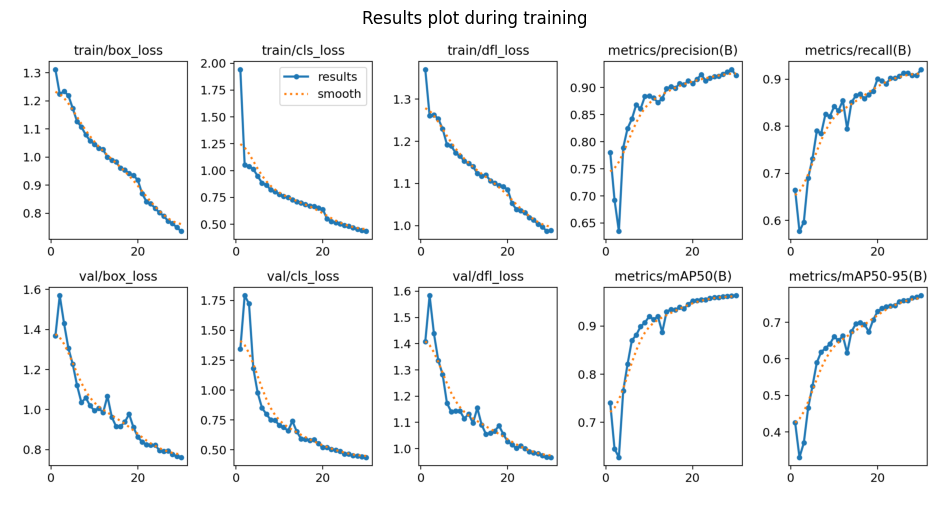

In [9]:
# results.png 图片路径
image_path = '/kaggle/working/runs/detect/train/results.png'

# 读取图片
img = plt.imread(image_path)
# 创建一个图形窗口并显示图片
plt.figure(figsize = (12, 8))
plt.imshow(img)
plt.title('Results plot during training')
plt.axis('off')
plt.show()

## 验证安全头盔和反光背心检测模型

In [10]:
datasets_path = '/kaggle/input/datasets/niravnaik/safety-helmet-and-reflective-jacket/safety-Helmet-Reflective-Jacket'

# 加载训练好的最优模型
model = YOLO('/kaggle/working/runs/detect/train/weights/best.pt')
# 模型验证
yaml_path = os.path.join(datasets_path, 'data.yaml')
metrics = model.val(data = yaml_path)

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO11n summary (fused): 101 layers, 2,597,294 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.3±0.1 ms, read: 83.4±25.5 MB/s, size: 40.6 KB)
val: Scanning /kaggle/input/datasets/niravnaik/safety-helmet-and-reflective-jacket/safety-Helmet-Reflective-Jacket/valid/labels... 1575 images, 8 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1575/1575 812.1it/s 1.9s0.0s
WARNING ⚠️ val: Cache directory /kaggle/input/datasets/niravnaik/safety-helmet-and-reflective-jacket/safety-Helmet-Reflective-Jacket/valid is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 99/99 7.1it/s 14.0s0.1s
                   all       1575       5292      0.922      0.921      0.963      0.773
         Safety-Helmet       1290       2966      0.934       0.93      0.969      0.773
     Reflective-Jacket       1317       2326       0

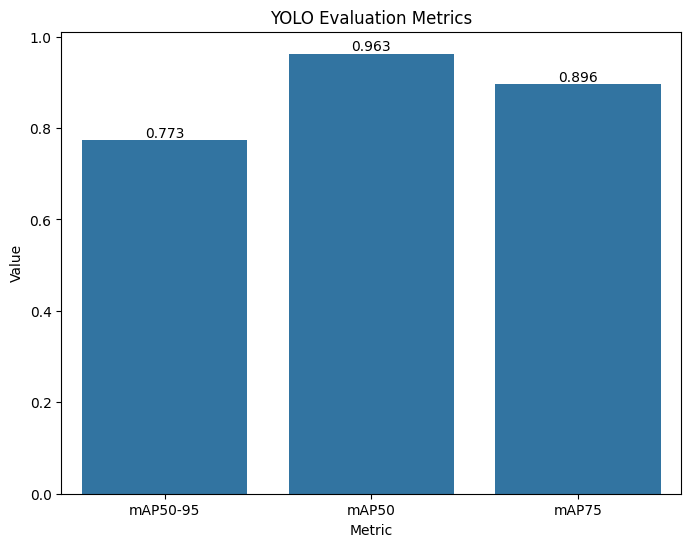

In [11]:
%matplotlib inline
# 创建柱状图
ax = sns.barplot(
    x = ['mAP50-95', 'mAP50', 'mAP75'],
    y = [metrics.box.map, metrics.box.map50, metrics.box.map75]
)
# 设置标题和轴标签
ax.set_title('YOLO Evaluation Metrics')
ax.set_xlabel('Metric')
ax.set_ylabel('Value')
fig = plt.gcf()
fig.set_size_inches(8, 6)
# 在柱状图上方添加数值
for p in ax.patches:
    ax.annotate(
        '{:.3f}'.format(p.get_height()),
        (p.get_x() + p.get_width() / 2, p.get_height()),
        ha = 'center', va = 'bottom'
    )
# 显示图形
plt.show()

## 安全头盔和反光背心检测模型预测


image 1/1 /kaggle/input/datasets/niravnaik/safety-helmet-and-reflective-jacket/safety-Helmet-Reflective-Jacket/test/images/helmet_jacket_07540.jpg: 640x640 1 Reflective-Jacket, 10.8ms
Speed: 3.3ms preprocess, 10.8ms inference, 1.5ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /kaggle/input/datasets/niravnaik/safety-helmet-and-reflective-jacket/safety-Helmet-Reflective-Jacket/test/images/helmet_jacket_07472.jpg: 640x640 3 Safety-Helmets, 3 Reflective-Jackets, 10.9ms
Speed: 0.9ms preprocess, 10.9ms inference, 1.9ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /kaggle/input/datasets/niravnaik/safety-helmet-and-reflective-jacket/safety-Helmet-Reflective-Jacket/test/images/helmet_jacket_08418.jpg: 640x640 8 Safety-Helmets, 10.9ms
Speed: 1.0ms preprocess, 10.9ms inference, 1.4ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /kaggle/input/datasets/niravnaik/safety-helmet-and-reflective-jacket/safety-Helmet-Reflective-Jacket/test/images/helmet_jacket_

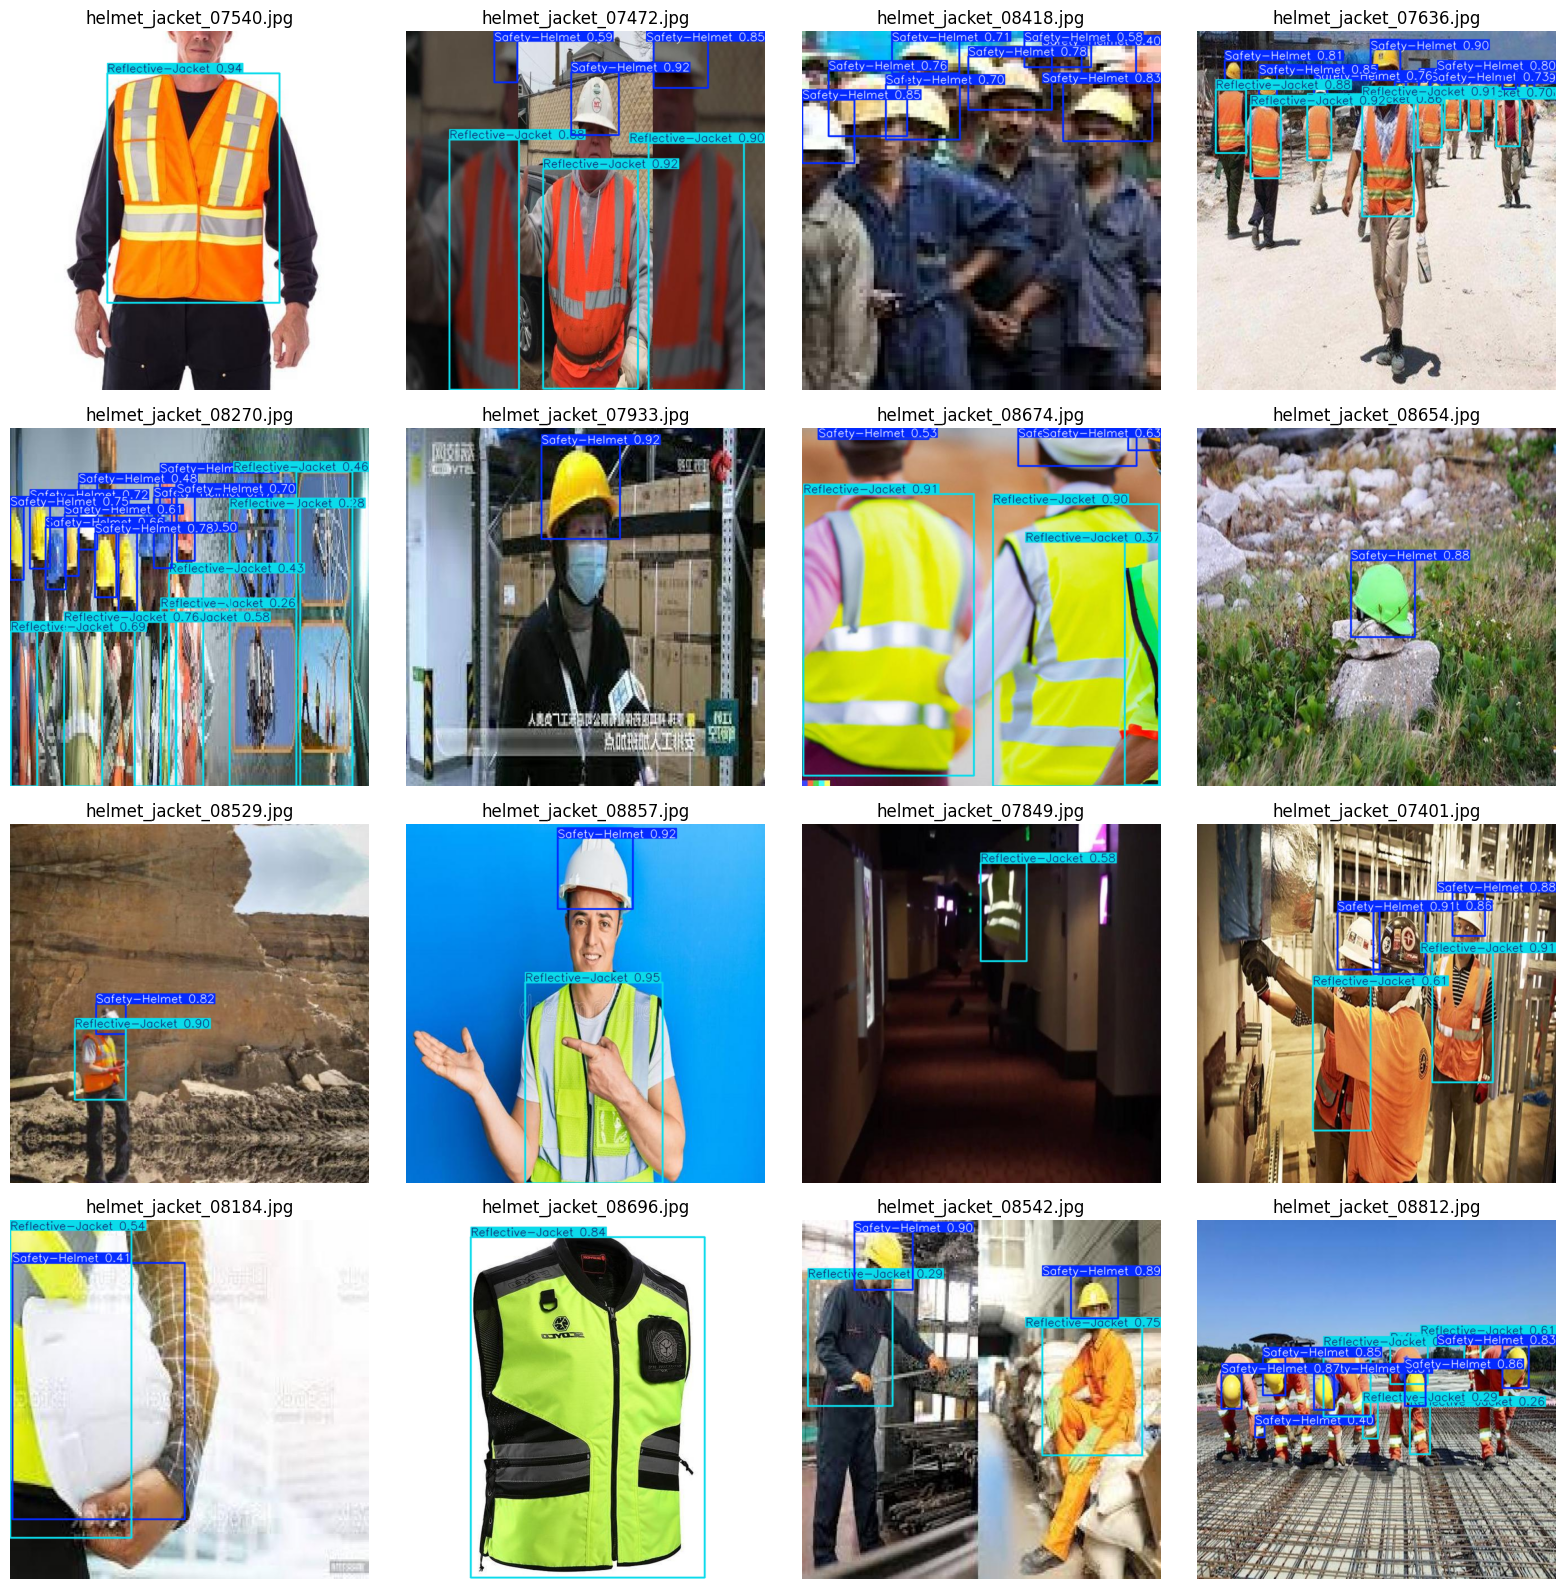

In [12]:
# 定义测试图片目录路径
test_img_dir = os.path.join(datasets_path, 'test/images')

def pred_images_show(images = test_img_dir, num_sample = 16):
    # 获取图片目录中的所有图片文件名
    image_files = os.listdir(images)
    # 随机选择指定数量的图片文件
    rand_imgs = random.sample(image_files, num_sample)

    # 创建一个 4 * 4 的图布局，用于显示图片
    fig, axes = plt.subplots(4, 4, figsize = (16, 16))
    # 遍历每个样本图片
    for i in range(num_sample):
        # 获取当前图片文件名
        image = rand_imgs[i]
        # 确定当前图片所在图布局中的位置
        ax = axes[i // 4, i % 4]
        # 使用模型对当前图片进行预测
        result_predict = model.predict(source = os.path.join(images, image))
        # 将预测结果的图片显示在子图中
        ax.imshow(cv2.cvtColor(result_predict[0].plot(), cv2.COLOR_BGR2RGB))
        # 设置子图的标题
        ax.set_title(image)
        # 关闭子图的坐标轴
        ax.axis('off')
    # 调整子图布局，使其紧凑
    plt.tight_layout()
    # 显示图片
    plt.show()

# 调用函数显示预测图片
pred_images_show()
        

In [15]:
!ffmpeg -y \
    -loglevel panic \
    -i /kaggle/input/datasets/justinwshj/videos/videos/video.mp4 \
    output.mp4

In [16]:
from IPython.display import Video
Video("output.mp4", width = 960, embed = True)

In [18]:
# 使用 yolo 进行对象跟踪
# 参数 model 指定使用的模型权重文件的路径
# 参数 source 指定输入视频文件的路径
# 参数 show 指定是否实时显示跟踪结果
!yolo track \
    model = '/kaggle/working/runs/detect/train/weights/best.pt' \
    source = '/kaggle/working/output.mp4' \
    show = True

requirements: Ultralytics requirement ['lap>=0.5.12'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 2 packages in 274ms
Prepared 1 package in 41ms
Installed 1 package in 1ms
 + lap==0.5.14

requirements: AutoUpdate success ✅ 1.1s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect

WARNING ⚠️ Environment does not support cv2.imshow() or PIL Image.show()

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
YOLO11n summary (fused): 101 layers, 2,597,294 parameters, 0 gradients, 6.4 GFLOPs

video 1/1 (frame 1/167) /kaggle/working/output.mp4: 352x640 2 Safety-Helmets, 2 Reflective-Jackets, 8.9ms
video 1/1 (frame 2/167) /kaggle/working/output.mp4: 352x640 2 Safety-Helmets, 2 Reflective-Jackets, 8.9ms
video 1/1 (frame 3/167) /kaggle/working/output.mp4: 352x640 2 Safety-Helmets, 2 Reflective-Jackets, 10.3ms
video 1/1 (frame 4/167) /kaggle/working/output.mp4: 352x640 2 Safety-Helmets, 2 Re

In [19]:
!ffmpeg -y \
    -loglevel panic \
    -i /kaggle/working/runs/detect/track/output.avi \
    result_out.mp4

In [20]:
Video('result_out.mp4', width = 960)

In [21]:
!zip -q -r result.zip /kaggle/working/*